# 07｜IMDB NLP 矩陣實驗：14 組 Validation 比較＋最終 Test

**版本區分：**前半部為原先的 Test 前選模歷史快照（14 組 Validation）。後半部為鎖定模型後的一次性官方 Test 獨立評估結果。測試前版本已原封保留為 07_IMDB_Results_Comparison_PRETEST.ipynb；原選模檔 SHA256 不變。Notebook 只讀取保存的 Test 成績與逐筆預測，**不再訓練或進行新一輪模型推論**。

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path('/workspace/imdb_matrix_experiment/variants/dedup_v1_1')
assert ROOT.is_dir()
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.common import file_hash
from src.phase4_compare import ALIASES, load_and_check, research_questions
policy,manifest,runs=load_and_check()
lock=json.loads((ROOT/'results/model_selection_lock.json').read_text())
assert lock['status']=='LOCKED_BEFORE_FINAL_TEST'
assert lock['official_test_not_evaluated'] is True
assert lock['runs_registry_sha256']==file_hash(ROOT/'results/runs.csv')
assert lock['policy_sha256']==file_hash(ROOT/'config/phase4_selection_policy.yaml')
print('Dataset:',manifest['version'])
print('Runs:',len(runs))
print('Model selection:',lock['selected_overall'],lock['selected_deep_learning'])
print('Historical status at selection lock: Test NOT EVALUATED')


Dataset: dedup_v1.1
Runs: 14
Model selection: ML-04-s42 DL-05-s42
Historical status at selection lock: Test NOT EVALUATED


## 1. 14 組模型的統一結果表

F1 是正面類別（label=1）的 binary F1；所有分數都重新根據 Validation prediction CSV 與 Label 計算驗證過。傳統模型沒有 DL 的 trainable_params 欄位，不能填成 0。


In [2]:
table=runs[['overall_rank','run_id','display_name','family','val_accuracy','val_precision','val_recall',
            'val_f1','val_loss','trainable_params','epochs_completed','train_time_sec','inference_time_sec']].copy()
display(table.round(4))
assert len(table)==14 and list(table.overall_rank)==list(range(1,15))
print('Best overall:',table.iloc[0]['display_name'],round(table.iloc[0].val_f1,5))


,overall_rank,run_id,display_name,family,val_accuracy,val_precision,val_recall,val_f1,val_loss,trainable_params,epochs_completed,train_time_sec,inference_time_sec
0,1,ML-04-s42,TF-IDF + SVC,Traditional ML,0.8921,0.8874,0.8992,0.8932,NaN,NaN,NaN,274.2794,48.0708
1,2,ML-02-s42,BoW + SVC,Traditional ML,0.8767,0.8771,0.8775,0.8773,NaN,NaN,NaN,194.5276,34.2910
2,3,DL-05-s42,LSTM + EarlyStopping,Deep Learning,0.8454,0.8503,0.8401,0.8452,0.3724,1242305.0,4.0,9.9430,0.2102
3,4,DL-06-s42,LSTM + Dropout + ES,Deep Learning,0.8366,0.8346,0.8413,0.8379,0.4065,1242305.0,5.0,12.3065,0.2213
4,5,DL-02-s42,LSTM,Deep Learning,0.8247,0.8525,0.7871,0.8185,0.7924,1242305.0,10.0,13.6681,0.1738
5,6,DL-10-s42,Bidirectional GRU,Deep Learning,0.8216,0.8399,0.7967,0.8177,0.9158,1263873.0,10.0,32.6914,0.3146
6,7,DL-08-s42,LSTM + GRU,Deep Learning,0.8067,0.7945,0.8297,0.8117,0.9441,1267265.0,10.0,33.5900,0.3040
7,8,DL-03-s42,GRU,Deep Learning,0.8099,0.8125,0.8080,0.8102,0.7745,1231937.0,10.0,12.2460,0.1640
8,9,DL-04-s42,LSTM + Dropout,Deep Learning,0.7962,0.7908,0.8080,0.7993,0.7951,1242305.0,10.0,24.6234,0.2244
9,10,DL-09-s42,Bidirectional LSTM,Deep Learning,0.8004,0.8186,0.7742,0.7958,0.5446,1284609.0,10.0,34.4293,0.3392


Best overall: TF-IDF + SVC 0.89323


## 2. F1 總排名圖：傳統 ML 與深度學習共同呈現

不把 Validation 最佳分數稱作最終 Test 泛化表現。


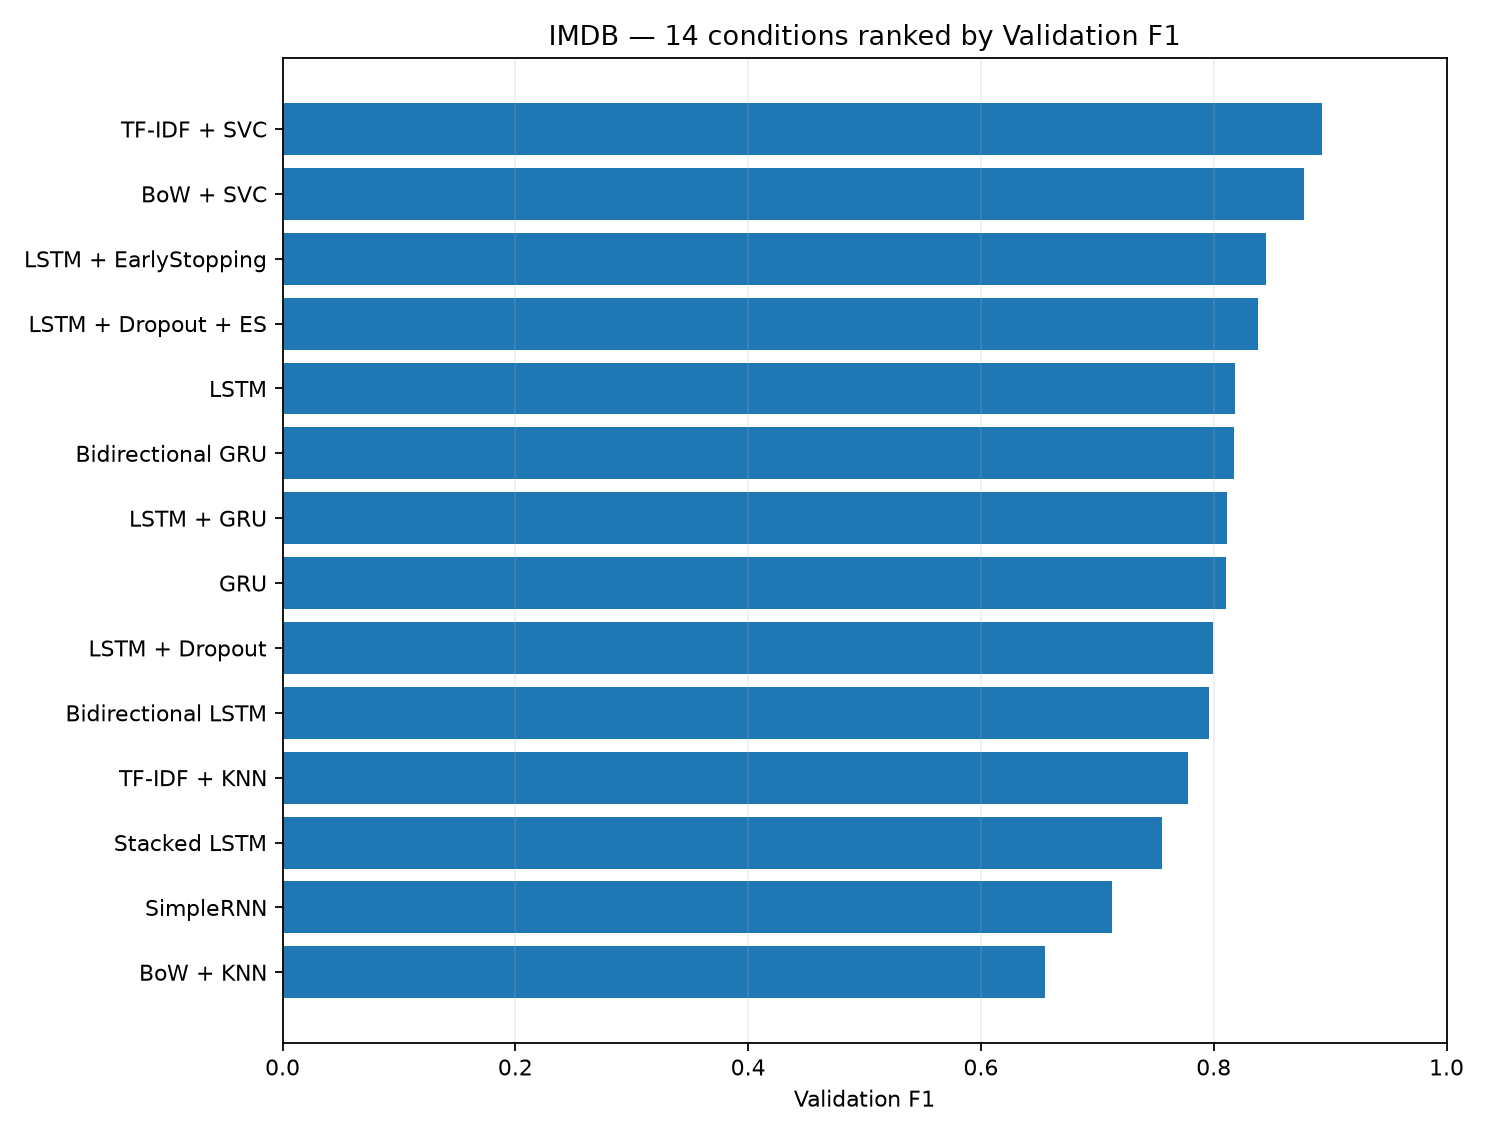

In [3]:
pic=ROOT/'results/figures/07_all_14_validation_f1.png'
assert pic.is_file()
display(Image(filename=str(pic),width=850))


## 3. 研究問題 RQ1、RQ2：文字表示與分類器（2×2）

**RQ1** 固定分類器，檢查 BoW ↔ TF-IDF；**RQ2** 固定文字表示，檢查 KNN ↔ SVC。
KNN 使用 cosine brute，SVC 使用原生 sklearn.svm.SVC(kernel='linear')。


,RQ,comparison,Validation F1 difference (percentage points)
0,RQ1,TFIDF_vs_BoW_given_KNN,12.2488
1,RQ1,TFIDF_vs_BoW_given_SVC,1.5950
2,RQ2,SVC_vs_KNN_given_BoW,22.1931
3,RQ2,SVC_vs_KNN_given_TFIDF,11.5393
4,RQ3,LSTM_vs_SimpleRNN,10.5922
5,RQ3,GRU_vs_SimpleRNN,9.7689
6,RQ3,LSTM_vs_GRU,0.8233
7,RQ4,Dropout_only_vs_baseline,-1.9182
8,RQ4,ES_only_vs_baseline,2.6723
9,RQ4,Both_vs_baseline,1.9468


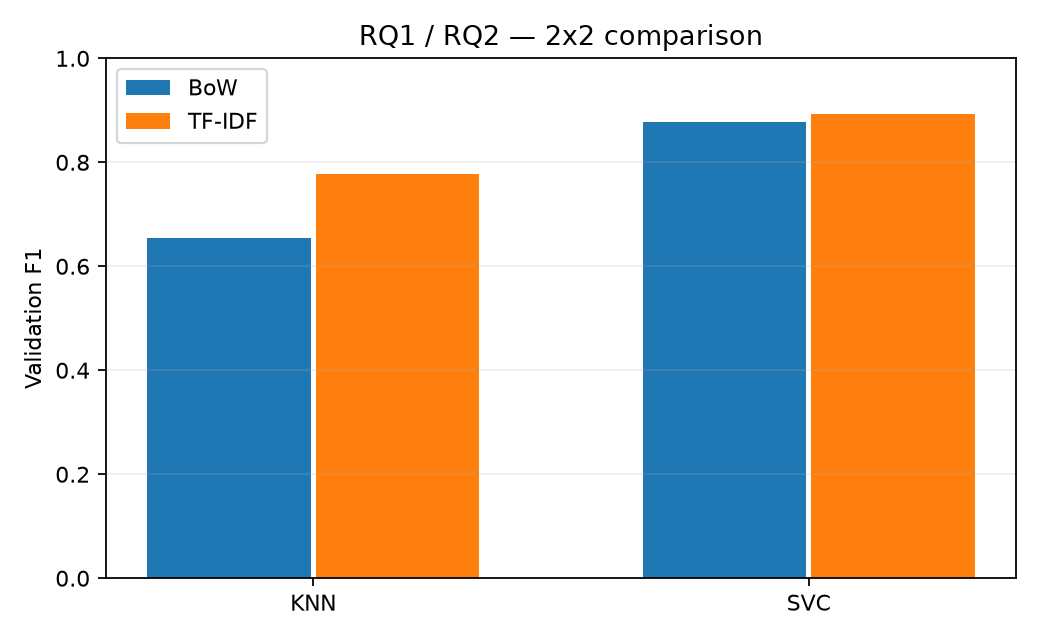

In [4]:
rq=json.loads((ROOT/'results/phase4_research_questions.json').read_text())
display(pd.DataFrame([
    {'RQ':group,'comparison':k,'Validation F1 difference (percentage points)':v}
    for group,values in rq.items() if group.startswith('RQ')
    for k,v in values.items()
]).round(4))
display(Image(filename=str(ROOT/'results/figures/07_traditional_2x2_f1.png'),width=580))


## 4. RQ3：SimpleRNN、LSTM、GRU

三組使用相同 160-token 序列、100-dim Embedding、64 hidden units、10 epochs、無 Dropout／EarlyStopping；參數量不同。比較 Validation 分數與實測成本。


,run_id,display_name,val_accuracy,val_f1,val_loss,trainable_params,train_time_sec,inference_time_sec
12,DL-01-s42,SimpleRNN,0.7050,0.7125,1.1702,1210625.0,18.8431,0.4337
4,DL-02-s42,LSTM,0.8247,0.8185,0.7924,1242305.0,13.6681,0.1738
7,DL-03-s42,GRU,0.8099,0.8102,0.7745,1231937.0,12.2460,0.1640


DL-01-s42 SimpleRNN


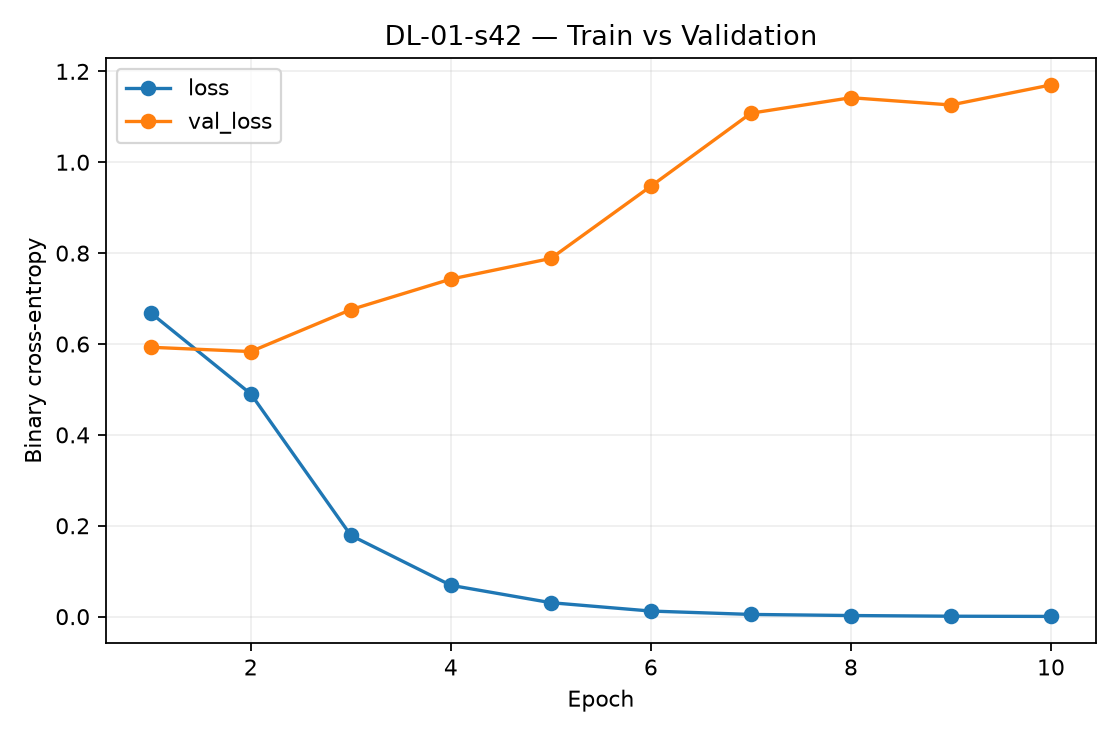

DL-02-s42 LSTM


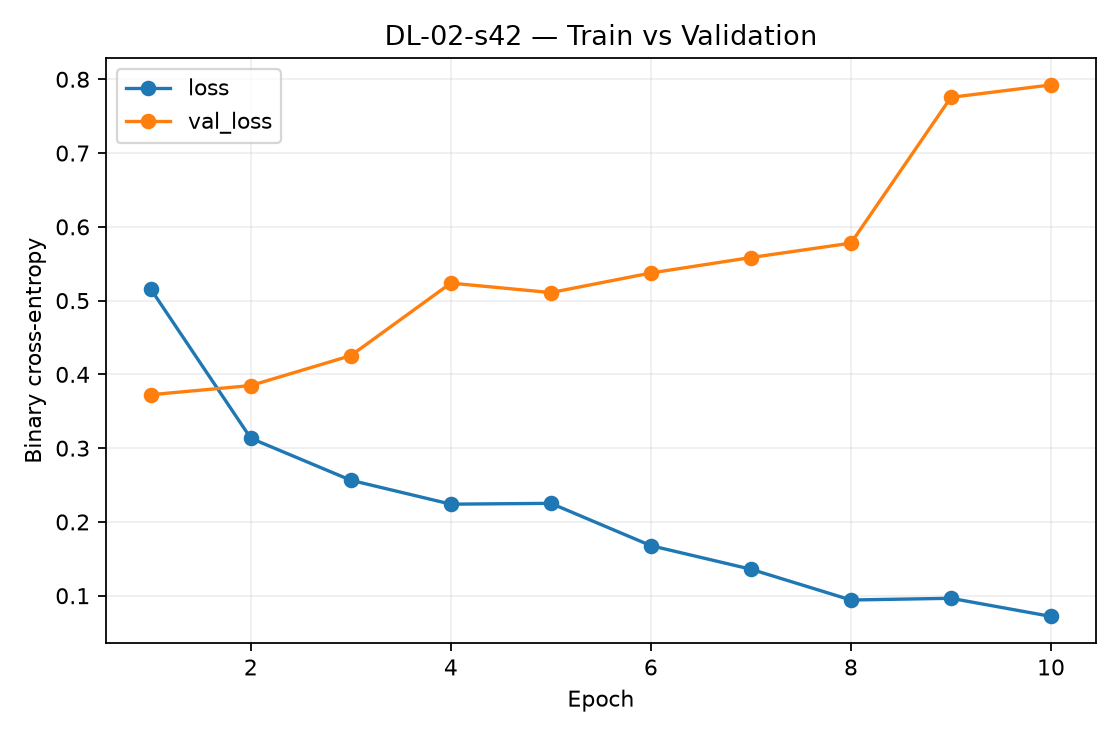

DL-03-s42 GRU


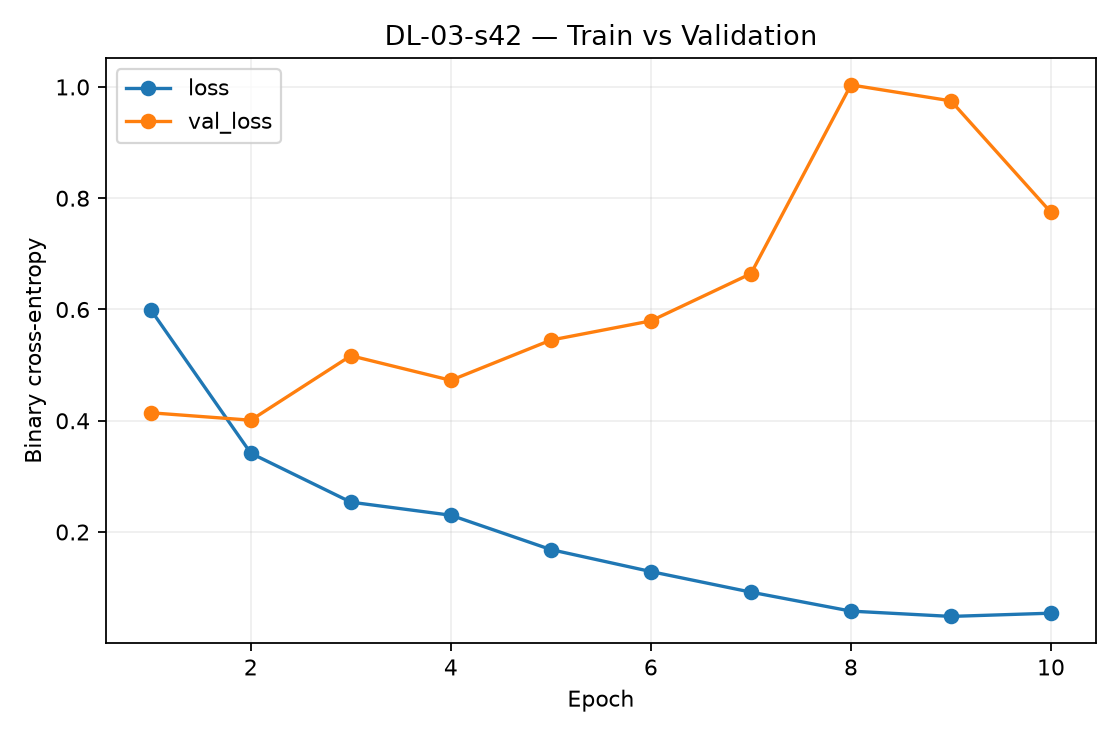

In [5]:
single=runs[runs.run_id.isin(['DL-01-s42','DL-02-s42','DL-03-s42'])].sort_values('run_id')
display(single[['run_id','display_name','val_accuracy','val_f1','val_loss','trainable_params',
                'train_time_sec','inference_time_sec']].round(4))
for rid in ('DL-01-s42','DL-02-s42','DL-03-s42'):
    print(rid,ALIASES[rid])
    display(Image(filename=str(ROOT/f'results/figures/{rid}_learning_curve.png'),width=460))


## 5. RQ4：LSTM Dropout × Early Stopping

2×2 包含同一份原始 LSTM 基準 DL-02（沒有重訓）。
Early Stopping 使用 val_loss、patience=3、restore_best_weights=True。標註真實訓練 Epoch，不拿不同 Epoch 的實驗當成等成本比較。


,run_id,display_name,val_accuracy,val_f1,val_loss,epochs_completed,trainable_params,train_time_sec
0,DL-02-s42,LSTM,0.8247,0.8185,0.7924,10.0,1242305.0,13.6681
1,DL-04-s42,LSTM + Dropout,0.7962,0.7993,0.7951,10.0,1242305.0,24.6234
2,DL-05-s42,LSTM + EarlyStopping,0.8454,0.8452,0.3724,4.0,1242305.0,9.9430
3,DL-06-s42,LSTM + Dropout + ES,0.8366,0.8379,0.4065,5.0,1242305.0,12.3065


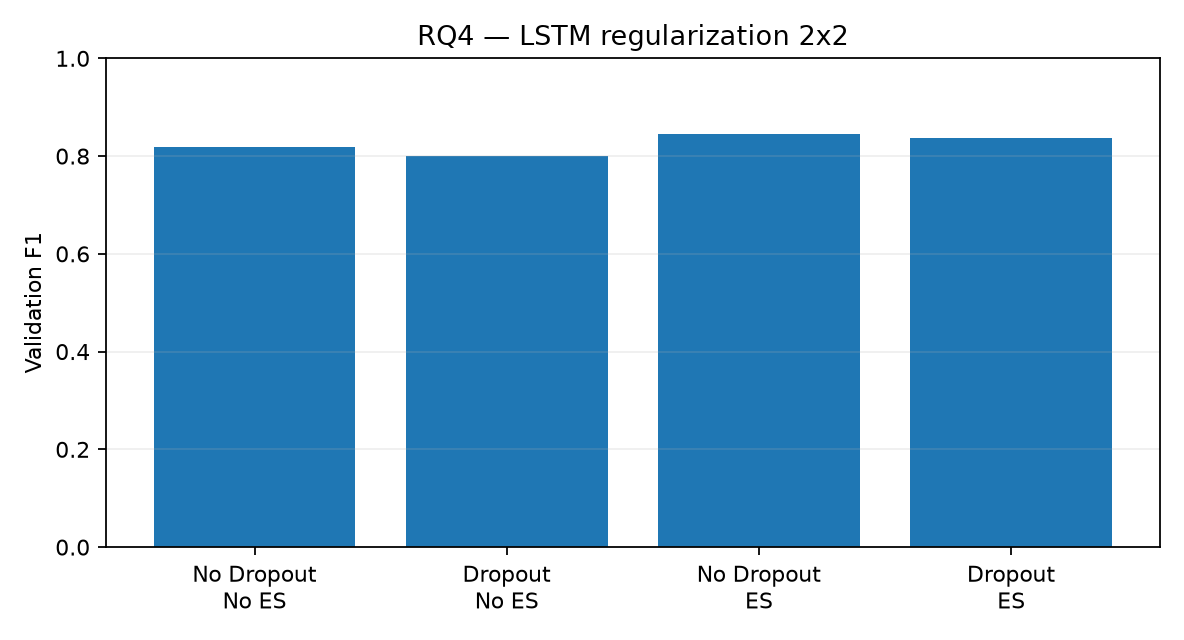

DL-02-s42 Loss curve


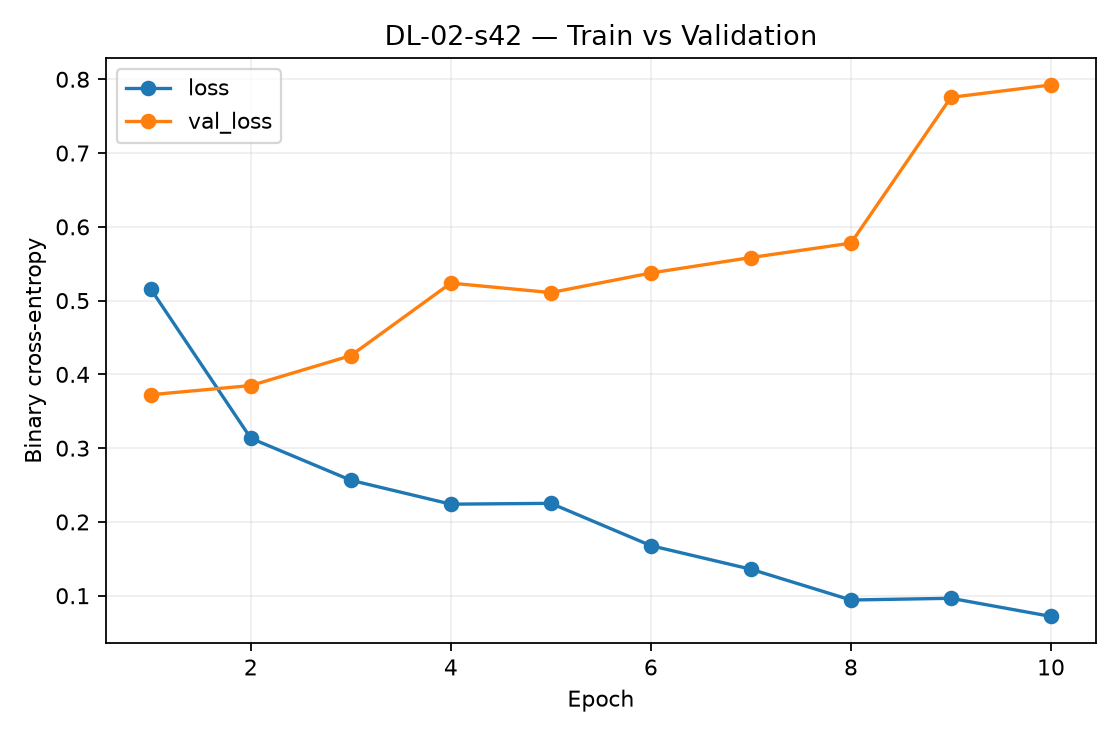

DL-05-s42 Loss curve


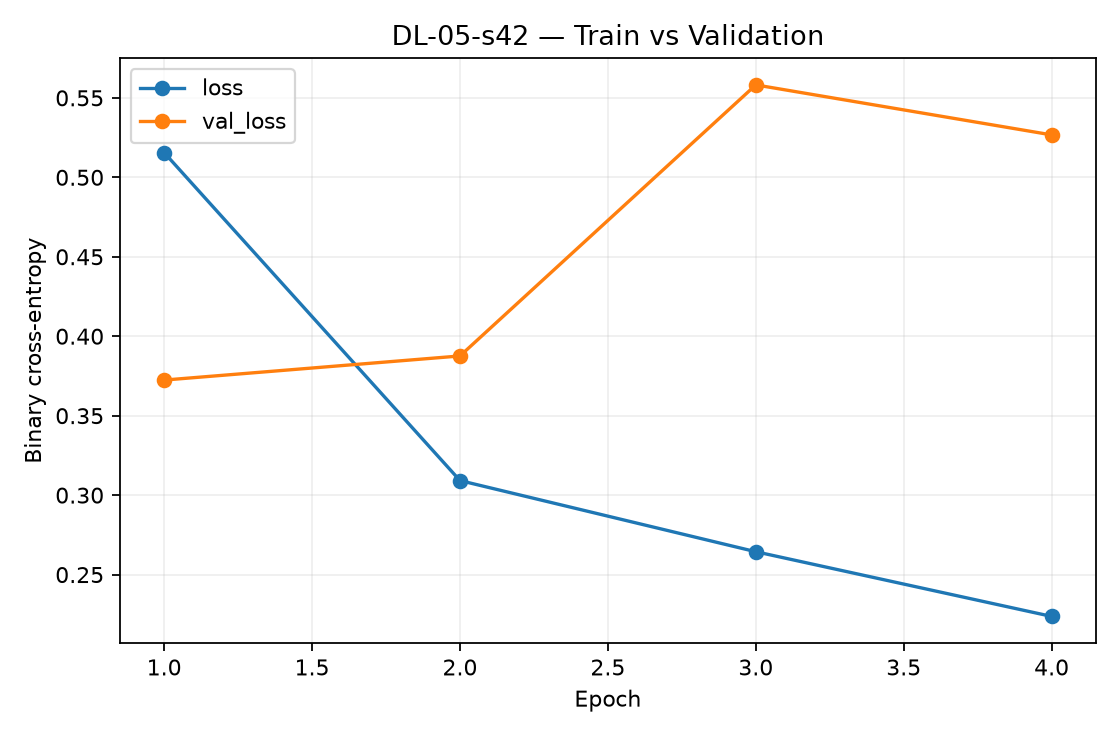

In [6]:
four=['DL-02-s42','DL-04-s42','DL-05-s42','DL-06-s42']
lstm=runs.set_index('run_id').loc[four].reset_index()
display(lstm[['run_id','display_name','val_accuracy','val_f1','val_loss',
              'epochs_completed','trainable_params','train_time_sec']].round(4))
display(Image(filename=str(ROOT/'results/figures/07_regularization_2x2_f1.png'),width=650))
for rid in ('DL-02-s42','DL-05-s42'):
    print(rid,'Loss curve')
    display(Image(filename=str(ROOT/f'results/figures/{rid}_learning_curve.png'),width=540))


## 6. RQ5：堆疊、混合及雙向網路

Stacked LSTM、LSTM+GRU、Bidirectional LSTM、Bidirectional GRU 均不使用 Dropout 或 Early Stopping，訓練 10 epochs。比較與相應單層基準的差異；並列模型參數量以免錯認為等參數量實驗。


,run_id,display_name,val_accuracy,val_f1,trainable_params,train_time_sec
0,DL-02-s42,LSTM,0.8247,0.8185,1242305.0,13.6681
1,DL-03-s42,GRU,0.8099,0.8102,1231937.0,12.2460
2,DL-07-s42,Stacked LSTM,0.7782,0.7556,1275329.0,32.6990
3,DL-08-s42,LSTM + GRU,0.8067,0.8117,1267265.0,33.5900
4,DL-09-s42,Bidirectional LSTM,0.8004,0.7958,1284609.0,34.4293
5,DL-10-s42,Bidirectional GRU,0.8216,0.8177,1263873.0,32.6914


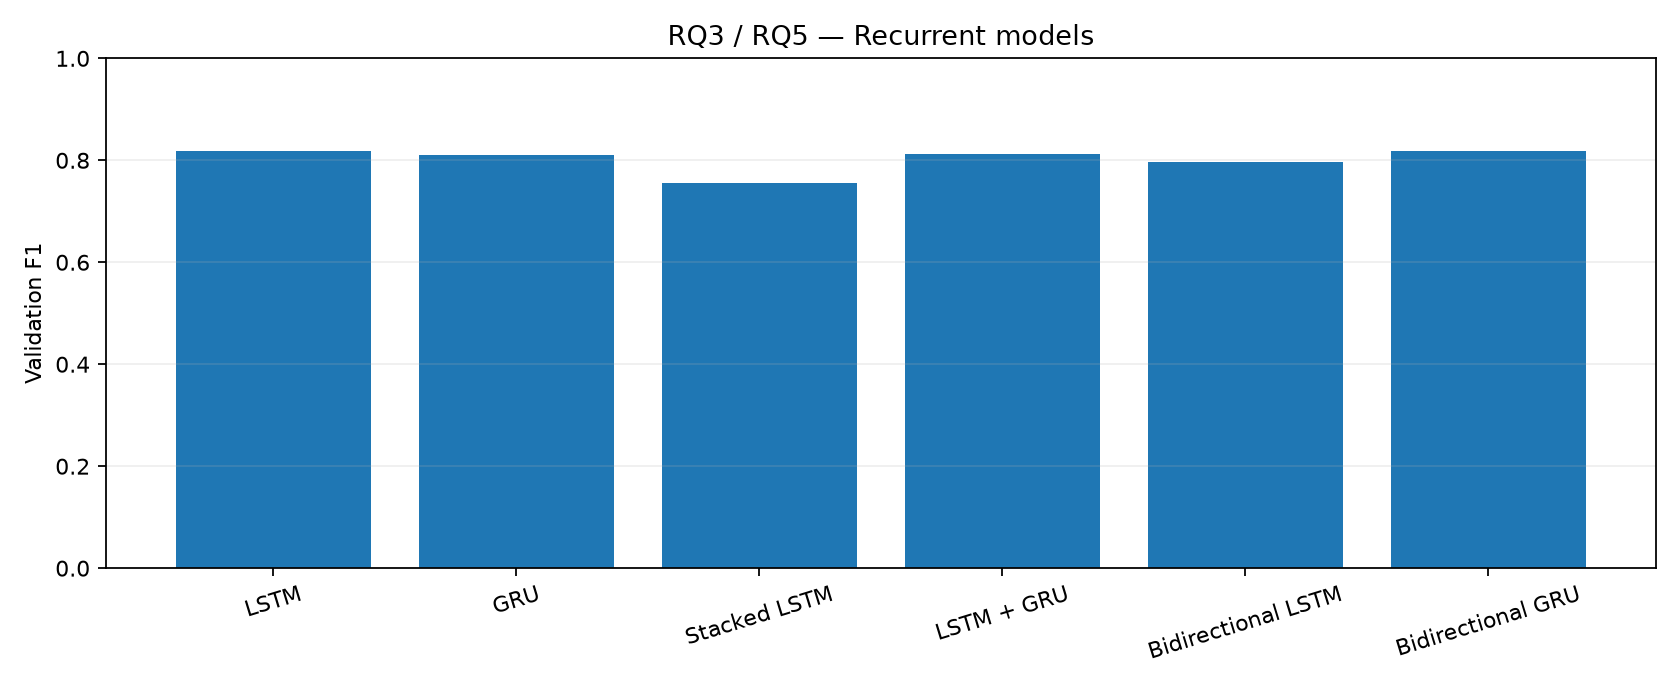

In [7]:
adv=['DL-02-s42','DL-03-s42','DL-07-s42','DL-08-s42','DL-09-s42','DL-10-s42']
advanced=runs.set_index('run_id').loc[adv].reset_index()
display(advanced[['run_id','display_name','val_accuracy','val_f1',
                 'trainable_params','train_time_sec']].round(4))
display(Image(filename=str(ROOT/'results/figures/07_advanced_rnn_f1.png'),width=900))


## 7. 效能－成本關係（僅比較深度學習組）

這張散佈圖只納入 DL 模型，X 軸為包含各 Epoch Validation 的訓練耗時。
**傳統 ML 的 fit 時間定義不同**：KNN 距離查詢通常屬於推論、SVC 訓練秒數含兩組 C 候選；不能將它們直接與 DL fit 秒數視為同一種成本。


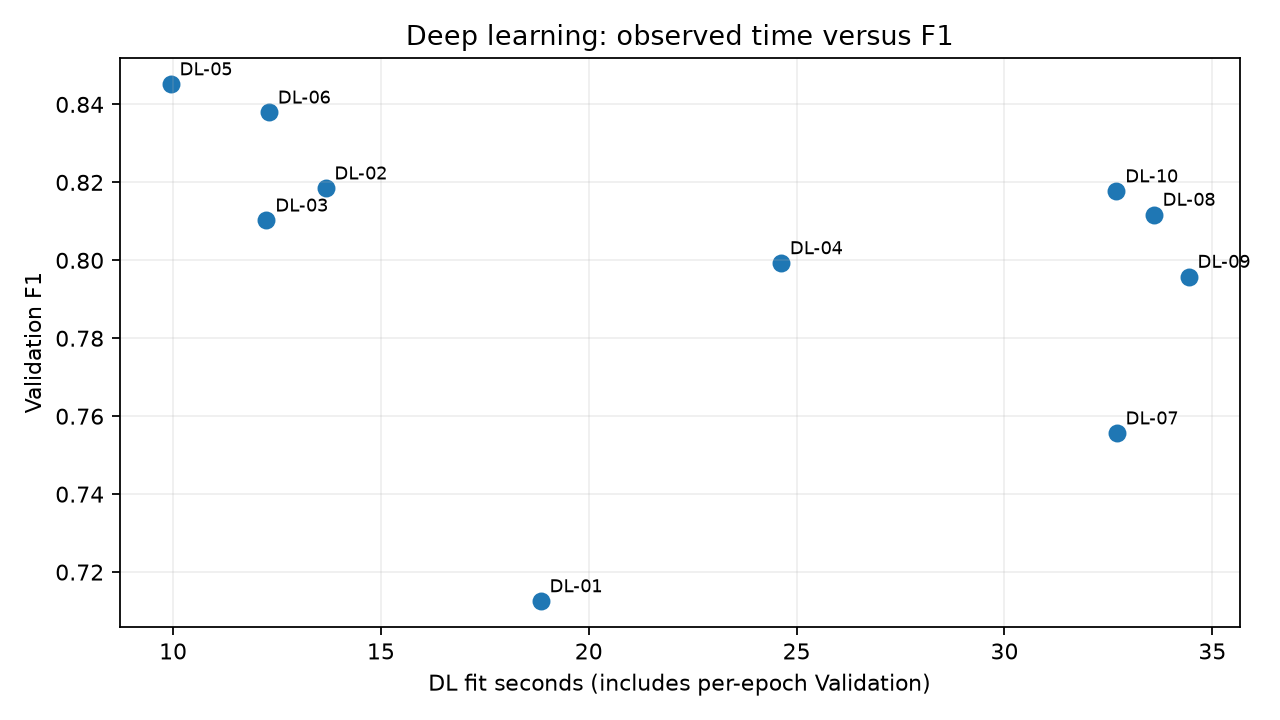

In [8]:
display(Image(filename=str(ROOT/'results/figures/07_deep_learning_cost_f1.png'),width=770))


## 8. 代表性 Confusion Matrix：兩個類別最佳模型

依 Validation F1 選出傳統 ML 代表與深度學習代表；兩張混淆矩陣均取 Validation 且計入 4,956 筆樣本。


ML-04-s42 TF-IDF + SVC


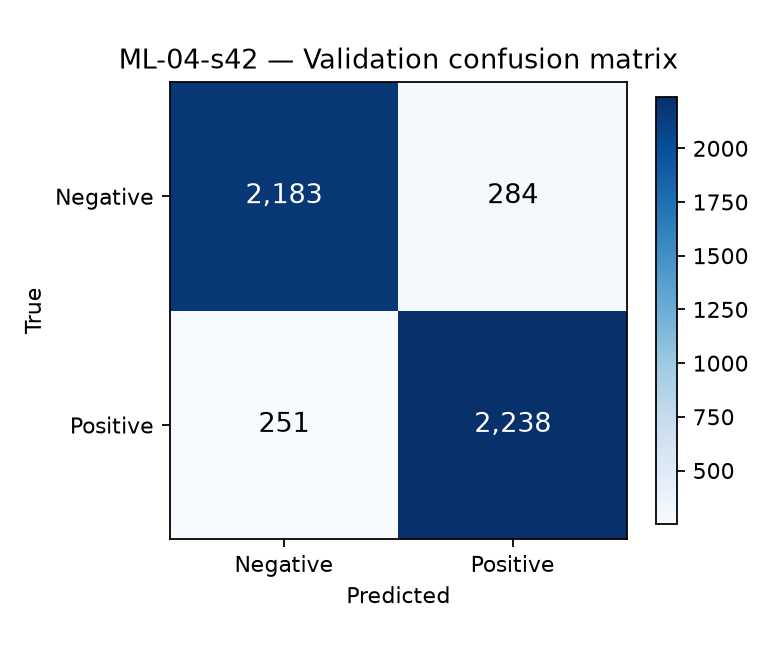

DL-05-s42 LSTM + EarlyStopping


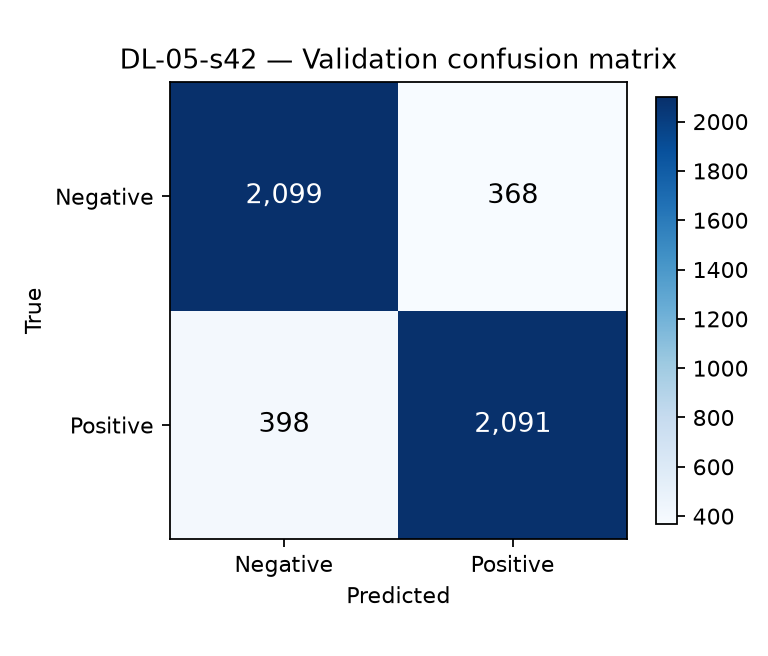

In [9]:
champions=[lock['selected_traditional_ml'],lock['selected_deep_learning']]
assert champions==['ML-04-s42','DL-05-s42']
for rid in champions:
    print(rid,ALIASES[rid])
    display(Image(filename=str(ROOT/f'results/figures/{rid}_val_confusion_matrix.png'),width=470))


## 9. Test 前模型選擇鎖定與來源驗證

鎖定檔含 14 組排名、候選選模政策、原始模型與預測檔的 SHA-256。
只有兩個預先選定的類別代表模型會列入下一階段官方 Test 計畫；**不得看 Test 再改選模型**。


In [10]:
assert len(lock['all14_ranking'])==14
assert lock['all14_ranking']==runs.run_id.tolist()
assert lock['official_test_not_evaluated']
for rid,item in lock['source_artifacts'].items():
    assert file_hash(ROOT/item['model_path'])==item['model_sha256'],rid
    assert file_hash(ROOT/item['validation_predictions_path'])==item['validation_predictions_sha256'],rid
assert pd.read_csv(ROOT/'results/runs.csv')[['test_accuracy','test_f1']].isna().all().all()
print('LOCK CHECK PASS: 14/14 saved model and prediction hashes matched')
print('Frozen for future final Test:',lock['future_final_test_scope'])
print('Model inference performed in this Notebook: 0; read-only output')


LOCK CHECK PASS: 14/14 saved model and prediction hashes matched
Frozen for future final Test: ['ML-04-s42', 'DL-05-s42']
Model inference performed in this Notebook: 0; read-only output


## 10. 研究結論、限制與下一步

**Validation 結論**：TF-IDF + SVC 在全部 14 組中排名第一；LSTM + EarlyStopping 是深度學習組最佳。固定 seed=42 並不等於已證實統計顯著差異。

**重要限制**：超過半數評論長於 160 tokens；官方 Test 內部重複評論仍保留；沒有另外進行語意近似去重；各架構參數量與訓練成本未完整匹配。選做的 GloVe 尚未執行。

**下一階段**：先驗收 Test 前鎖定，再依固定範圍對官方 Test 執行一次獨立評估，完成真正的 Gate E，任何 Test 後修改都要明確標成探索性分析。


# 11｜官方 Test：鎖定後獨立評估

事前依 Validation F1 選定兩個代表：**ML-04-s42** 與 **DL-05-s42**。每組只對原版 25,000 筆官方 Test 評估一次。本段**只讀取**既有 final_test 預測檔，沒有再執行模型推論或調參。

前面提到的 Test 未評估，是選模鎖定當時的歷史狀態。

In [11]:
from pathlib import Path
import json,numpy as np,pandas as pd
from IPython.display import Image,display
F=ROOT/'results/final_test'
final=json.loads((F/'locked_final_test_metrics.json').read_text(encoding='utf8'))
lock_now=json.loads((ROOT/'results/model_selection_lock.json').read_text(encoding='utf8'))
assert final['status']=='OFFICIAL_TEST_EVALUATED_ONCE'
assert final['scope']==lock_now['future_final_test_scope']==['ML-04-s42','DL-05-s42']
assert final['model_selection_lock_sha256']==file_hash(ROOT/'results/model_selection_lock.json')
assert final['model_evaluations_performed']==2 and not final['test_based_retuning']
print('Official Test: evaluated after selection lock; fixed scope',final['scope'])
print('Official Test rows:',final['official_test_rows'])
print('New model inferences performed in Notebook 07: zero')

Official Test: evaluated after selection lock; fixed scope ['ML-04-s42', 'DL-05-s42']
Official Test rows: 25000
New model inferences performed in Notebook 07: zero


## 12｜最終 Test 指標與 Validation 對照

分別呈現 Test Accuracy、Precision、Recall、F1；LSTM 的 BCE 可計算，但 SVC 無同一定義的 Binary Cross-Entropy，因此不填造 ML Test Loss。Test 不能拿來重新選模。

,run_id,model,Validation Accuracy,Test Accuracy,Validation F1,Test F1,Test Precision,Test Recall,Test BCE (if applicable)
0,ML-04-s42,TF-IDF + SVC,0.8921,0.8810,0.8932,0.8803,0.8850,0.8758,NaN
1,DL-05-s42,LSTM + EarlyStopping,0.8454,0.8344,0.8452,0.8315,0.8464,0.8170,0.3871


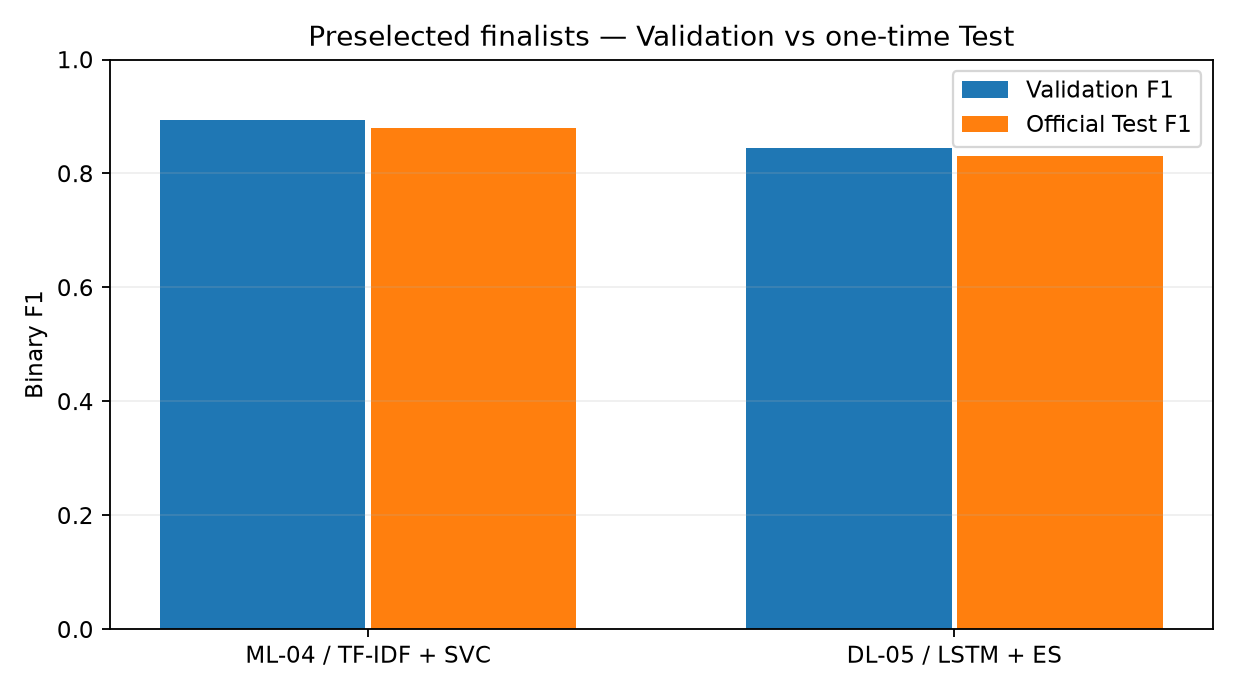

In [12]:
v=pd.read_csv(ROOT/'results/runs.csv').set_index('run_id')
records=[]
for rid in final['scope']:
    m=final['predictions_and_metrics'][rid]
    records.append({'run_id':rid,'model':m['model'],
       'Validation Accuracy':v.loc[rid,'val_accuracy'],
       'Test Accuracy':m['accuracy'],
       'Validation F1':v.loc[rid,'val_f1'],
       'Test F1':m['f1'],
       'Test Precision':m['precision'],
       'Test Recall':m['recall'],
       'Test BCE (if applicable)':m.get('test_loss')})
display(pd.DataFrame(records).round(4))
display(Image(filename=str(F/final['comparison_figure']),width=750))

## 13｜Test Confusion Matrix 與逐筆數據一致性

只對已保存的 25,000 筆 Test CSV 重新計算指標，**沒有重新執行原模型**；比對來源樣本 ID 與標籤後才接受結果。

ML-04-s42 Official Test F1 0.880338 CM [[11077, 1423], [1553, 10947]]


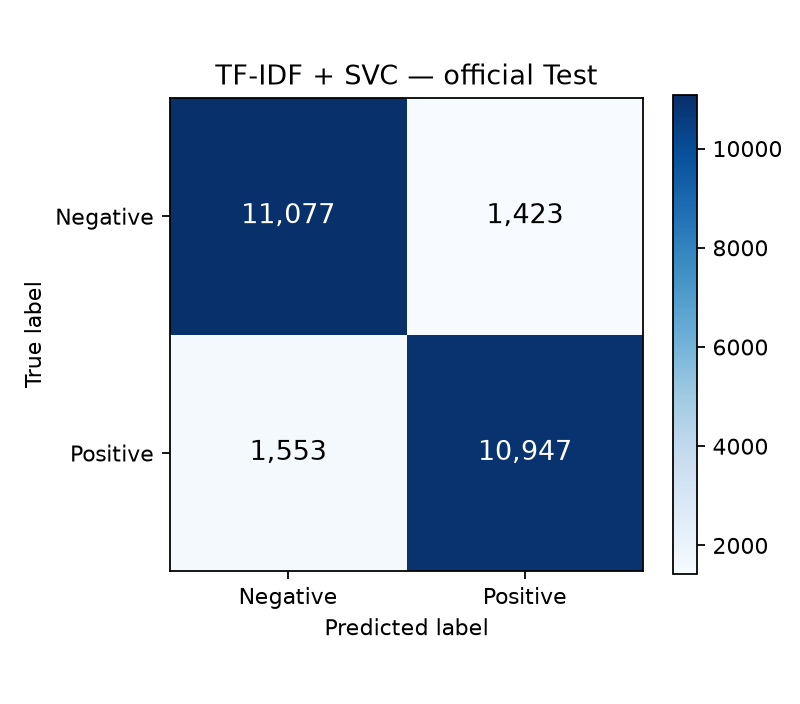

DL-05-s42 Official Test F1 0.831474 CM [[10647, 1853], [2287, 10213]]


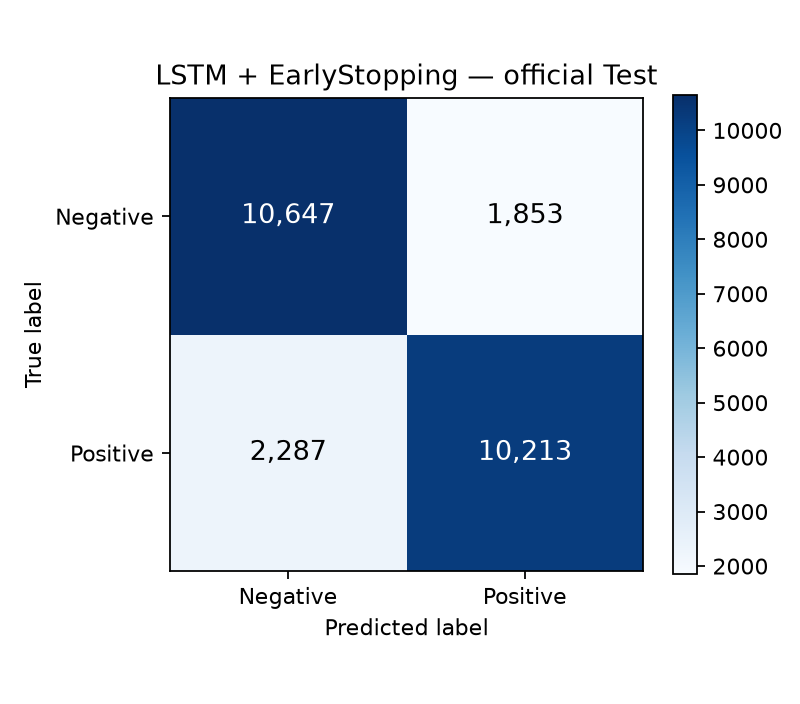

Recomputed stored Test metrics: PASS


In [13]:
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix
canonical=pd.read_parquet(ROOT/'data/processed/test.parquet')
for rid in final['scope']:
    m=final['predictions_and_metrics'][rid]
    file=F/m['predictions_csv']
    p=pd.read_csv(file)
    assert len(p)==len(canonical)==25000
    assert p.example_id.tolist()==canonical.example_id.tolist()
    assert p.label.tolist()==canonical.label.tolist()
    assert file_hash(file)==m['predictions_sha256']
    assert abs(accuracy_score(p.label,p.prediction)-m['accuracy'])<1e-12
    assert abs(f1_score(p.label,p.prediction)-m['f1'])<1e-12
    assert confusion_matrix(p.label,p.prediction,labels=[0,1]).tolist()==m['confusion_matrix']
    print(rid,'Official Test F1',round(m['f1'],6),'CM',m['confusion_matrix'])
    display(Image(filename=str(F/f'{rid}_test_confusion_matrix.png'),width=410))
print('Recomputed stored Test metrics: PASS')

## 14｜研究結論與限制

- RQ1～RQ5 與 14 組模型排名使用 Validation；最終只有鎖定的兩組代表使用 Test。
- 單一 seed 42，沒有統計顯著性結論；模型參數量及計時範圍並非完全一致。
- 160-token 截斷超過半數評論，官方 Test 內部重複仍保留，未進行近似語意去重。
- 無 Test 後重訓、改參數或改選模型。

正式結果與 Gate E 驗收報告在 results/final_test 與 results/GATE_E_REPORT.md。